Adatok sikeresen betöltve!

--- 1. Legtöbb egyéni világbajnoki cím ---
          fullName  titles
    Lewis Hamilton       7
Michael Schumacher       7
       Juan Fangio       5
    Max Verstappen       4
  Sebastian Vettel       4
       Alain Prost       4
        Niki Lauda       3
      Ayrton Senna       3
      Jack Brabham       3
     Nelson Piquet       3


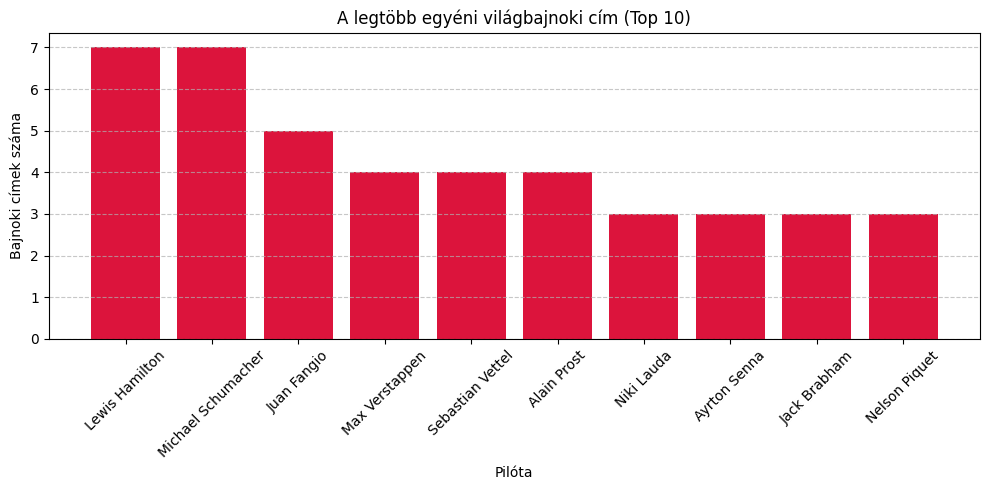



--- 2. Legtöbb konstruktőri világbajnoki cím ---
         name  titles
      Ferrari      16
      McLaren      10
     Williams       9
     Mercedes       8
     Red Bull       6
   Team Lotus       4
      Renault       2
 Lotus-Climax       2
Cooper-Climax       2
Brabham-Repco       2


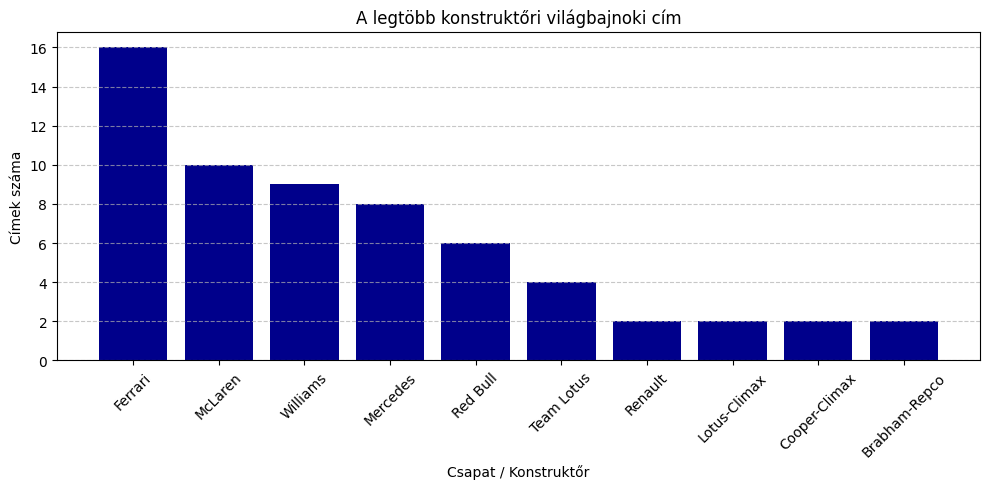



--- 3. Leggyorsabb kör 2020-ban ---
Pálya: Bahrain International Circuit (Sakhir, Bahrain)
Verseny: Sakhir Grand Prix
Pilóta: George Russell (Köridő: 0:55.404)


--- 4. Világbajnok pilóták, akik a 14. rajthelyen kívülről (P15+) nyertek ---
          fullName  wins_from_p15_plus
   Fernando Alonso                   1
    Kimi Räikkönen                   1
Michael Schumacher                   1
    Jackie Stewart                   1
    Max Verstappen                   1


--- 5. A legtöbb világbajnokavatás helyszínei ---
                     Circuit  Title_Deciders
          Yas Marina Circuit              15
     Adelaide Street Circuit              11
                Watkins Glen               8
Autódromo Hermanos Rodríguez               7
  Autódromo José Carlos Pace               7
              Suzuka Circuit               6
Autodromo Nazionale di Monza               6
        Circuit de Pedralbes               2
    Las Vegas Street Circuit               2
               Fuji Sp

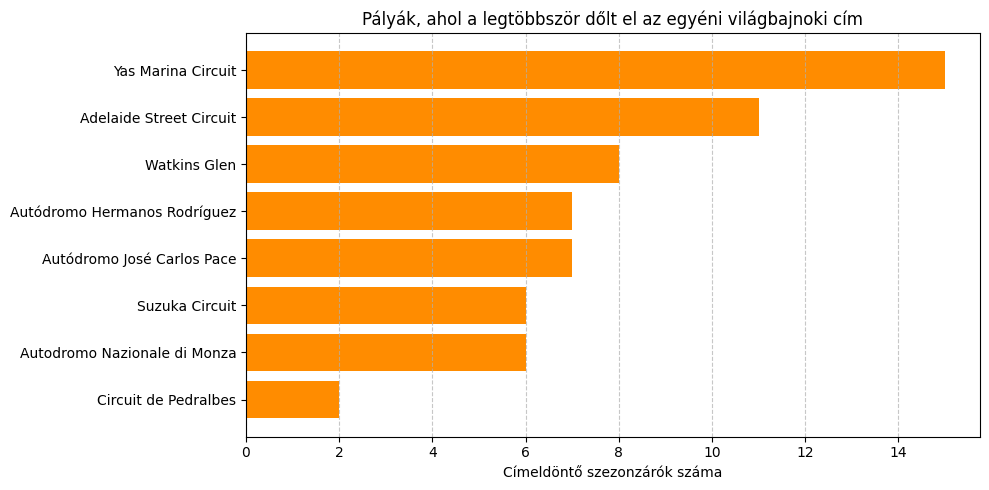

In [6]:
import os
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ==========================================
# 0. ADATOK BETÖLTÉSE ÉS ELŐKÉSZÍTÉSE
# ==========================================
# Ha a results.csv még a ZIP-ben van, kicsomagoljuk
if not os.path.exists("results.csv") and os.path.exists("F1 Data.zip"):
    with zipfile.ZipFile("F1 Data.zip", "r") as z:
        z.extractall(".")

drivers = pd.read_csv("drivers.csv")
constructors = pd.read_csv("constructors.csv")
circuits = pd.read_csv("circuits.csv")
driver_standings = pd.read_csv("driver_standings.csv")
constructor_standings = pd.read_csv("constructor_standings.csv")
lap_times = pd.read_csv("lap_times.csv")
races = pd.read_csv("races.csv")
results = pd.read_csv("results.csv")

# Típuskonverziók az összehasonlításokhoz
driver_standings["position_clean"] = pd.to_numeric(
    driver_standings["position"], errors="coerce"
)
constructor_standings["position_clean"] = pd.to_numeric(
    constructor_standings["position"], errors="coerce"
)

# Szezonok utolsó futamainak meghatározása (ahol eldől a bajnokság)
last_races = (
    races.sort_values(["year", "round"])
    .groupby("year")
    .last()
    .reset_index()[["year", "raceId", "circuitId"]]
)

# Egyéni világbajnokok szűrése
champions_standings = pd.merge(last_races, driver_standings, on="raceId")
champions = champions_standings[champions_standings["position_clean"] == 1]
champion_driver_ids = champions["driverId"].unique()

print("Adatok sikeresen betöltve!\n" + "=" * 60 + "\n")


# ==========================================
# 1. KÉRDÉS: Kik szerezték a legtöbb világbajnoki győzelmet?
# ==========================================
print("--- 1. Legtöbb egyéni világbajnoki cím ---")
titles = champions["driverId"].value_counts().reset_index()
titles.columns = ["driverId", "titles"]
top_drivers = pd.merge(titles, drivers, on="driverId").sort_values(
    "titles", ascending=False
)

top10_drivers = top_drivers.head(10).copy()
top10_drivers["fullName"] = (
    top10_drivers["forename"] + " " + top10_drivers["surname"]
)
print(top10_drivers[["fullName", "titles"]].to_string(index=False))

# Grafikon - 1. Kérdés
plt.figure(figsize=(10, 5))
plt.bar(top10_drivers["fullName"], top10_drivers["titles"], color="crimson")
plt.title("A legtöbb egyéni világbajnoki cím (Top 10)")
plt.xlabel("Pilóta")
plt.ylabel("Bajnoki címek száma")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("\n" + "=" * 60 + "\n")


# ==========================================
# 2. KÉRDÉS: Melyik csapat nyerte a legtöbb világbajnokságot?
# ==========================================
print("--- 2. Legtöbb konstruktőri világbajnoki cím ---")
c_champions_standings = pd.merge(
    last_races, constructor_standings, on="raceId"
)
c_champions = c_champions_standings[c_champions_standings["position_clean"] == 1]

c_titles = c_champions["constructorId"].value_counts().reset_index()
c_titles.columns = ["constructorId", "titles"]
top_constructors = pd.merge(c_titles, constructors, on="constructorId").sort_values(
    "titles", ascending=False
)

top10_constructors = top_constructors.head(10)
print(top10_constructors[["name", "titles"]].to_string(index=False))

# Grafikon - 2. Kérdés
plt.figure(figsize=(10, 5))
plt.bar(
    top10_constructors["name"], top10_constructors["titles"], color="darkblue"
)
plt.title("A legtöbb konstruktőri világbajnoki cím")
plt.xlabel("Csapat / Konstruktőr")
plt.ylabel("Címek száma")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()

print("\n" + "=" * 60 + "\n")


# ==========================================
# 3. KÉRDÉS: Melyik pályán futották a leggyorsabb kört 2020-ban?
# ==========================================
print("--- 3. Leggyorsabb kör 2020-ban ---")
races_2020 = races[races["year"] == 2020]
laps_2020 = pd.merge(lap_times, races_2020, on="raceId")

if not laps_2020.empty:
    fastest_lap_idx = laps_2020["milliseconds"].idxmin()
    fastest_lap = laps_2020.loc[fastest_lap_idx]
    circuit_info = circuits[
        circuits["circuitId"] == fastest_lap["circuitId"]
    ].iloc[0]
    driver_info = drivers[
        drivers["driverId"] == fastest_lap["driverId"]
    ].iloc[0]
    race_info = races[
        races["raceId"] == fastest_lap["raceId"]
    ].iloc[0]

    print(
        f"Pálya: {circuit_info['name']} ({circuit_info['location']}, {circuit_info['country']})"
    )
    print(f"Verseny: {race_info['name']}")
    print(
        f"Pilóta: {driver_info['forename']} {driver_info['surname']} (Köridő: {fastest_lap['time_x']})"
    )
else:
    print("A 2020-as szezonzáróra vonatkozó köridők nem találhatóak.")

print("\n" + "=" * 60 + "\n")


# ==========================================
# 4. KÉRDÉS: Melyik világbajnok pilótáknak sikerült a 14. rajthelyen kívülről nyernie?
# ==========================================
print(
    "--- 4. Világbajnok pilóták, akik a 14. rajthelyen kívülről (P15+) nyertek ---"
)

# Számmá alakítás a biztonságos szűréshez
results_copy = results.copy()
results_copy["grid_clean"] = pd.to_numeric(results_copy["grid"], errors="coerce")
results_copy["positionOrder_clean"] = pd.to_numeric(results_copy["positionOrder"], errors="coerce")

# Szűrés: Futamgyőzelem és Rajthely > 14
wins_from_back = results_copy[
    (results_copy["grid_clean"] > 14) & (results_copy["positionOrder_clean"] == 1)
]

# Csak az egyéni világbajnok pilóták szűrése
champ_back_wins = wins_from_back[
    wins_from_back["driverId"].isin(champion_driver_ids)
]

# Összesítés pilótánként
champ_win_counts = (
    champ_back_wins["driverId"].value_counts().reset_index()
)
champ_win_counts.columns = ["driverId", "wins_from_p15_plus"]

champ_back_win_drivers = pd.merge(
    champ_win_counts, drivers, on="driverId"
).sort_values("wins_from_p15_plus", ascending=False)
champ_back_win_drivers["fullName"] = (
    champ_back_win_drivers["forename"]
    + " "
    + champ_back_win_drivers["surname"]
)

print(
    champ_back_win_drivers[["fullName", "wins_from_p15_plus"]].to_string(
        index=False
    )
)

print("\n" + "=" * 60 + "\n")


# ==========================================
# 5. KÉRDÉS: Melyik versenypályán szerezték meg legtöbbször a világbajnoki győzelmet?
# ==========================================
print("--- 5. A legtöbb világbajnokavatás helyszínei ---")
champ_circuits = pd.merge(last_races, circuits, on="circuitId")
circuit_counts = champ_circuits["name"].value_counts().reset_index()
circuit_counts.columns = ["Circuit", "Title_Deciders"]

print(circuit_counts.head(10).to_string(index=False))

# Grafikon - 5. Kérdés
plt.figure(figsize=(10, 5))
plt.barh(
    circuit_counts["Circuit"].head(8),
    circuit_counts["Title_Deciders"].head(8),
    color="darkorange",
)
plt.title("Pályák, ahol a legtöbbször dőlt el az egyéni világbajnoki cím")
plt.xlabel("Címeldöntő szezonzárók száma")
plt.gca().invert_yaxis()
plt.grid(axis="x", linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()